In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

files = sorted(Path("phaseclass").glob("*_phaseclass.csv"))

print("Number of files:", len(files))

Number of files: 22


In [2]:
features = [
    "Vx_mps",
    "Vy_mps",
    "yawRate_radps",
    "roadWheelAngle_rad",
    "ayCG_mps2",
    "axCG_mps2",
    "throttleCmd_percent",
    "brake_fl_bar",
    "brake_fr_bar",
    "brake_rl_bar",
    "brake_rr_bar",
    "engineTorque_Nm",
    "engine_rpm",
    "wheelspeed_fl",
    "wheelspeed_fr",
    "wheelspeed_rl",
    "wheelspeed_rr",
    "LSDengage_percent",
    "rollRate_radps",
    "pitchRate_radps"
]

In [3]:
window = 5

X_windows = []
y_windows = []
groups = []

for file in files:

    df = pd.read_csv(file)

    df = df.dropna(
        subset=features + ["phase_label"]
    ).reset_index(drop=True)

    X = df[features].values
    y = df["phase_label"].values

    for i in range(window - 1, len(df)):

        X_window = X[i-window+1:i+1]

        X_windows.append(
            X_window.flatten()
        )

        y_windows.append(
            y[i]
        )

        groups.append(
            file.stem
        )

X_temporal = np.array(X_windows)
y_temporal = np.array(y_windows)
groups = np.array(groups)

print("Temporal X shape:", X_temporal.shape)
print("Labels shape:", y_temporal.shape)
print("Number of runs:", len(np.unique(groups)))

Temporal X shape: (545687, 100)
Labels shape: (545687,)
Number of runs: 22


In [4]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        X_temporal,
        y_temporal,
        groups=groups
    )
)

X_train = X_temporal[train_idx]
X_test = X_temporal[test_idx]

y_train = y_temporal[train_idx]
y_test = y_temporal[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining runs:")
print(np.unique(groups[train_idx]))

print("\nTesting runs:")
print(np.unique(groups[test_idx]))

Training samples: 432314
Testing samples: 113373

Training runs:
['2023-10_3_phaseclass' '2023-10_4_phaseclass' '2023-10_5_phaseclass'
 '2023-10_6_phaseclass' '2023-10_7_phaseclass' '2023-10_8_phaseclass'
 '2023-10_phaseclass' '2023-11_10_phaseclass' '2023-11_11_phaseclass'
 '2023-11_1_phaseclass' '2023-11_3_phaseclass' '2023-11_5_phaseclass'
 '2023-11_6_phaseclass' '2023-11_7_phaseclass' '2023-11_8_phaseclass'
 '2023-11_9_phaseclass' '2023-11_phaseclass']

Testing runs:
['2023-10_1_phaseclass' '2023-10_2_phaseclass' '2023-10_9_phaseclass'
 '2023-11_2_phaseclass' '2023-11_4_phaseclass']


In [5]:
rf_temporal = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_temporal.fit(
    X_train,
    y_train
)

print("Temporal Random Forest trained")

Temporal Random Forest trained


In [6]:
y_pred_temporal = rf_temporal.predict(
    X_test
)

In [7]:
print(
    classification_report(
        y_test,
        y_pred_temporal,
        digits=4,
        zero_division=0
    )
)

                  precision    recall  f1-score   support

INITIATING_DRIFT     0.5802    0.8315    0.6835      2884
          NORMAL     0.9955    0.9843    0.9899    110460
 SUSTAINED_DRIFT     0.0000    0.0000    0.0000        29

        accuracy                         0.9802    113373
       macro avg     0.5252    0.6053    0.5578    113373
    weighted avg     0.9847    0.9802    0.9818    113373



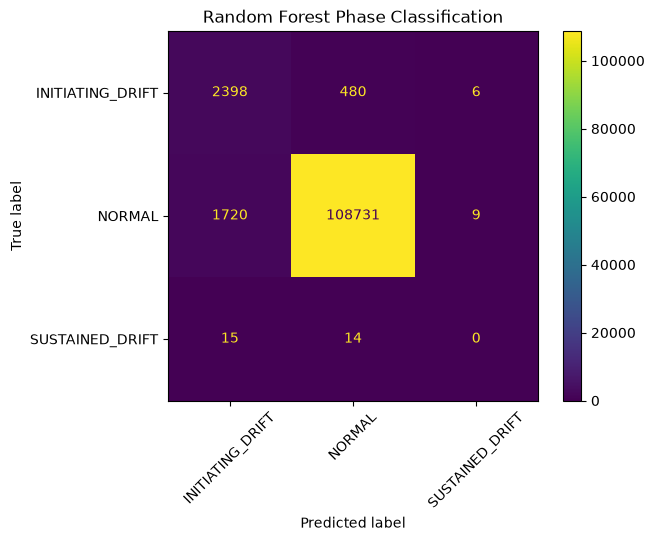

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_temporal,
    xticks_rotation=45
)

plt.title("Random Forest Phase Classification")
plt.grid(False)
plt.show()

In [13]:
import joblib

model_package = {
    "model": rf_temporal,
    "features": features,
    "window": window,
    "classes": rf_temporal.classes_
}

joblib.dump(
    model_package,
    "temporal_rf_drift_model.pkl"
)

print("Model saved as temporal_rf_drift_model.pkl")

Model saved as temporal_rf_drift_model.pkl


INITIATING_DRIFT: AP = 0.8003
NORMAL: AP = 0.9998
SUSTAINED_DRIFT: AP = 0.0578


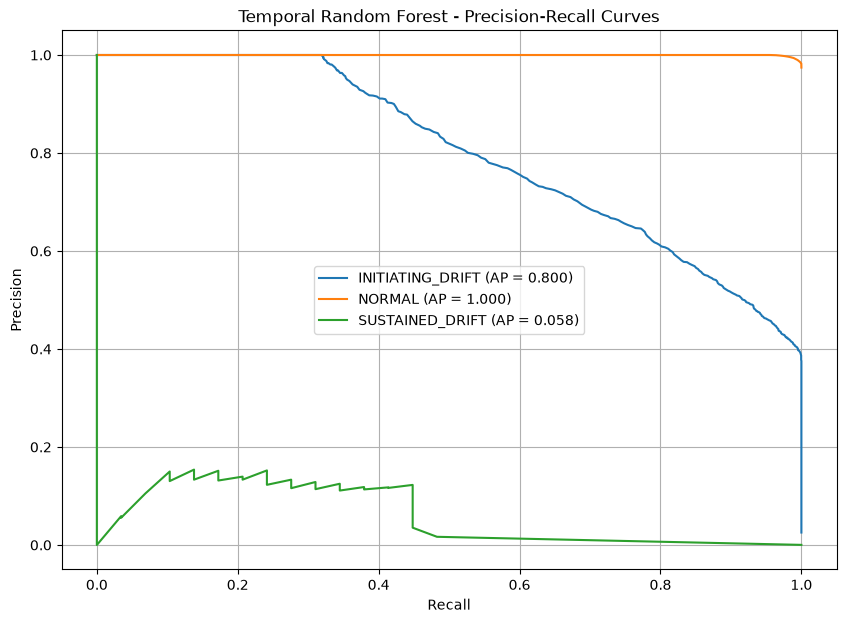

In [14]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score
import matplotlib.pyplot as plt

classes = rf_temporal.classes_

y_test_bin = label_binarize(
    y_test,
    classes=classes
)

y_prob = rf_temporal.predict_proba(X_test)

plt.figure(figsize=(10, 7))

for i, cls in enumerate(classes):

    precision, recall, _ = precision_recall_curve(
        y_test_bin[:, i],
        y_prob[:, i]
    )

    ap = average_precision_score(
        y_test_bin[:, i],
        y_prob[:, i]
    )

    plt.plot(
        recall,
        precision,
        label=f"{cls} (AP = {ap:.3f})"
    )

    print(
        f"{cls}: AP = {ap:.4f}"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Temporal Random Forest - Precision-Recall Curves")
plt.legend()
plt.grid()

plt.show()

In [15]:
macro_ap = average_precision_score(
    y_test_bin,
    y_prob,
    average="macro"
)

weighted_ap = average_precision_score(
    y_test_bin,
    y_prob,
    average="weighted"
)

print("Macro Average Precision:", macro_ap)
print("Weighted Average Precision:", weighted_ap)

Macro Average Precision: 0.6193309870044061
Weighted Average Precision: 0.994498074528657
